# CinemaPulse  -  Exploratory Data Analysis

**Objective:** Analyze the cleaned Cinema Ticket dataset to uncover sales patterns,
occupancy trends, and demand drivers that will inform the Streamlit dashboard and
forecasting model.

| Property | Value |
|---|---|
| **Dataset** | Kaggle Cinema Ticket (cleaned) |
| **Date coverage** | 2018-02-21 to 2018-11-04 (~8.5 months) |
| **Records** | 142,418 transaction-level rows |
| **Films** | 48 (numeric codes only) |
| **Cinemas** | 246 (numeric codes only) |
| **Daily aggregate** | 234 rows |

## 1. Setup & Imports

In [1]:
import sys, os, warnings
warnings.filterwarnings("ignore")

# Add project root so we can import from src/
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Plotting defaults
%matplotlib inline
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Output directory for report-ready figures
FIGURES_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_fig(fig, name, dpi=150):
    path = os.path.join(FIGURES_DIR, name)
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    print(f"  Saved -> {path}")

print("Setup complete.")

Setup complete.


## 2. Load Data

In [2]:
from src.data_loader import load_cleaned_data, load_daily_sales

df = load_cleaned_data()
daily = load_daily_sales()

print(f"Record-level : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Daily agg    : {daily.shape[0]:,} rows x {daily.shape[1]} columns")

Record-level : 142,418 rows x 23 columns
Daily agg    : 234 rows x 19 columns


## 3. Data Overview

Quick audit of the cleaned dataset: shape, types, descriptive stats, remaining issues.

In [3]:
print("=== Column Data Types ===")
print(df.dtypes.to_string())
print(f"\nMemory: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

=== Column Data Types ===
film_code                       int64
cinema_code                     int64
total_sales                     int64
tickets_sold                    int64
tickets_out                     int64
show_time                       int64
occu_perc                     float64
ticket_price                  float64
ticket_use                      int64
capacity                      float64
date                   datetime64[ns]
capacity_invalid                 bool
ticket_use_adjusted              bool
occu_perc_capped                 bool
year                            int64
month                           int64
quarter                         int64
day                             int64
day_of_week                     int64
day_name                       object
week_number                     int64
is_weekend                       bool
no_shows                        int64

Memory: 29.1 MB


In [4]:
# Descriptive statistics for key numeric columns
key_num = ["total_sales", "tickets_sold", "ticket_use", "occu_perc",
           "ticket_price", "capacity", "show_time", "no_shows"]
df[key_num].describe().round(2)

,total_sales,tickets_sold,ticket_use,occu_perc,ticket_price,capacity,show_time,no_shows
count,1.424180e+05,142418.00,142418.00,142363.00,142418.00,142363.00,142418.00,142418.00
mean,1.233589e+07,140.05,139.83,19.95,81229.35,854.58,3.93,0.22
std,3.063769e+07,279.73,279.52,22.62,33237.81,952.63,3.06,2.49
min,2.000000e+04,1.00,0.00,0.03,483.87,10.00,1.00,0.00
25%,1.260000e+06,18.00,18.00,3.75,60000.00,278.01,2.00,0.00
50%,3.710000e+06,50.00,50.00,10.34,79440.56,525.13,3.00,0.00
75%,1.110000e+07,143.00,143.00,28.19,100000.00,1038.25,5.00,0.00
max,1.262820e+09,8499.00,8499.00,100.00,700000.00,9692.10,60.00,311.00


In [5]:
# Remaining missing values and cleaning flags
missing = df.isnull().sum()
print("=== Remaining Missing Values ===")
print(missing[missing > 0].to_string() if missing.sum() > 0 else "None")
print()
for flag in ["capacity_invalid", "ticket_use_adjusted", "occu_perc_capped"]:
    print(f"  {flag}: {df[flag].sum():,} rows flagged")

=== Remaining Missing Values ===
occu_perc    55
capacity     55

  capacity_invalid: 55 rows flagged
  ticket_use_adjusted: 61 rows flagged
  occu_perc_capped: 168 rows flagged


## 4. Date Coverage & Gaps

Verify the date field and check for missing calendar days before doing time-series analysis.

In [6]:
print(f"Date range    : {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Unique dates  : {df['date'].nunique()}")
calendar_days = (df["date"].max() - df["date"].min()).days + 1
print(f"Calendar span : {calendar_days} days")

# Find gaps
all_dates = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
present_dates = pd.to_datetime(daily["date"])
missing_dates = all_dates.difference(present_dates)
print(f"Missing days  : {len(missing_dates)}")
if len(missing_dates) > 0:
    for d in sorted(missing_dates)[:15]:
        print(f"  {d.date()} ({d.day_name()})")

# Sparse early period
sparse = daily[daily["n_records"] < 50].sort_values("date")
print(f"\nSparse days (< 50 records): {len(sparse)}")
print(sparse[["date", "n_records", "n_films", "n_cinemas"]].to_string(index=False))

Date range    : 2018-02-21 to 2018-11-04
Unique dates  : 234
Calendar span : 257 days
Missing days  : 23
  2018-02-22 (Thursday)
  2018-02-24 (Saturday)
  2018-02-25 (Sunday)
  2018-02-26 (Monday)
  2018-02-27 (Tuesday)
  2018-02-28 (Wednesday)
  2018-03-01 (Thursday)
  2018-03-02 (Friday)
  2018-03-03 (Saturday)
  2018-03-04 (Sunday)
  2018-03-05 (Monday)
  2018-03-06 (Tuesday)
  2018-03-07 (Wednesday)
  2018-03-08 (Thursday)
  2018-03-09 (Friday)

Sparse days (< 50 records): 7
      date  n_records  n_films  n_cinemas
2018-02-21          1        1          1
2018-02-23          1        1          1
2018-06-05          4        4          1
2018-07-09          7        6          4
2018-09-21          1        1          1
2018-09-22         10        5          6
2018-10-30          2        2          1


## 5. Daily Sales & Ticket Demand Trends

Two time-series panels: revenue and ticket volume, each with a 7-day rolling
average to reveal the underlying trend through daily noise.

  Saved -> ..\reports\figures\daily_sales_trends.png


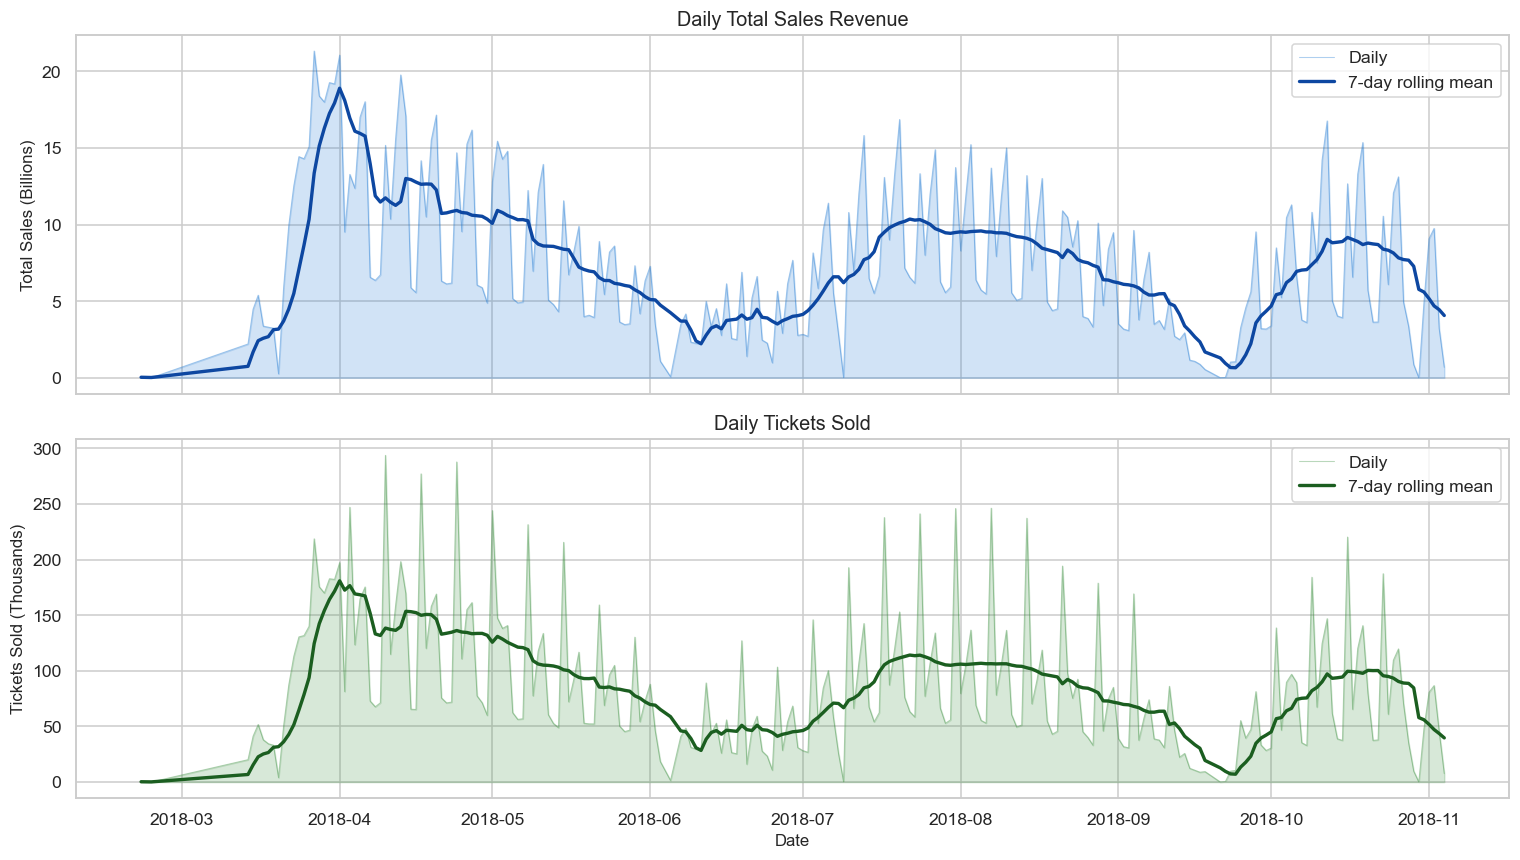

Daily total_sales  -- Mean: 7.51B, Median: 6.16B, Max: 21.32B
Daily tickets_sold -- Mean: 85.2K, Median: 67.5K, Max: 293.8K


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# --- Total Sales ---
axes[0].fill_between(daily["date"], daily["total_sales"] / 1e9,
                     alpha=0.20, color="#1976D2")
axes[0].plot(daily["date"], daily["total_sales"] / 1e9,
             alpha=0.35, linewidth=0.7, color="#1976D2", label="Daily")
axes[0].plot(daily["date"],
             (daily["total_sales"] / 1e9).rolling(7, min_periods=1).mean(),
             linewidth=2.2, color="#0D47A1", label="7-day rolling mean")
axes[0].set_ylabel("Total Sales (Billions)")
axes[0].set_title("Daily Total Sales Revenue")
axes[0].legend(loc="upper right")

# --- Tickets Sold ---
axes[1].fill_between(daily["date"], daily["tickets_sold"] / 1e3,
                     alpha=0.20, color="#388E3C")
axes[1].plot(daily["date"], daily["tickets_sold"] / 1e3,
             alpha=0.35, linewidth=0.7, color="#388E3C", label="Daily")
axes[1].plot(daily["date"],
             (daily["tickets_sold"] / 1e3).rolling(7, min_periods=1).mean(),
             linewidth=2.2, color="#1B5E20", label="7-day rolling mean")
axes[1].set_ylabel("Tickets Sold (Thousands)")
axes[1].set_xlabel("Date")
axes[1].set_title("Daily Tickets Sold")
axes[1].legend(loc="upper right")

plt.tight_layout()
save_fig(fig, "daily_sales_trends.png")
plt.show()
plt.close("all")

print(f"Daily total_sales  -- Mean: {daily['total_sales'].mean()/1e9:.2f}B, "
      f"Median: {daily['total_sales'].median()/1e9:.2f}B, "
      f"Max: {daily['total_sales'].max()/1e9:.2f}B")
print(f"Daily tickets_sold -- Mean: {daily['tickets_sold'].mean()/1e3:.1f}K, "
      f"Median: {daily['tickets_sold'].median()/1e3:.1f}K, "
      f"Max: {daily['tickets_sold'].max()/1e3:.1f}K")

## 6. Monthly Sales Patterns

February and November have partial coverage (8 and 4 days respectively), so
**average daily sales** is a fairer cross-month comparison than raw totals.

  Saved -> ..\reports\figures\monthly_sales.png


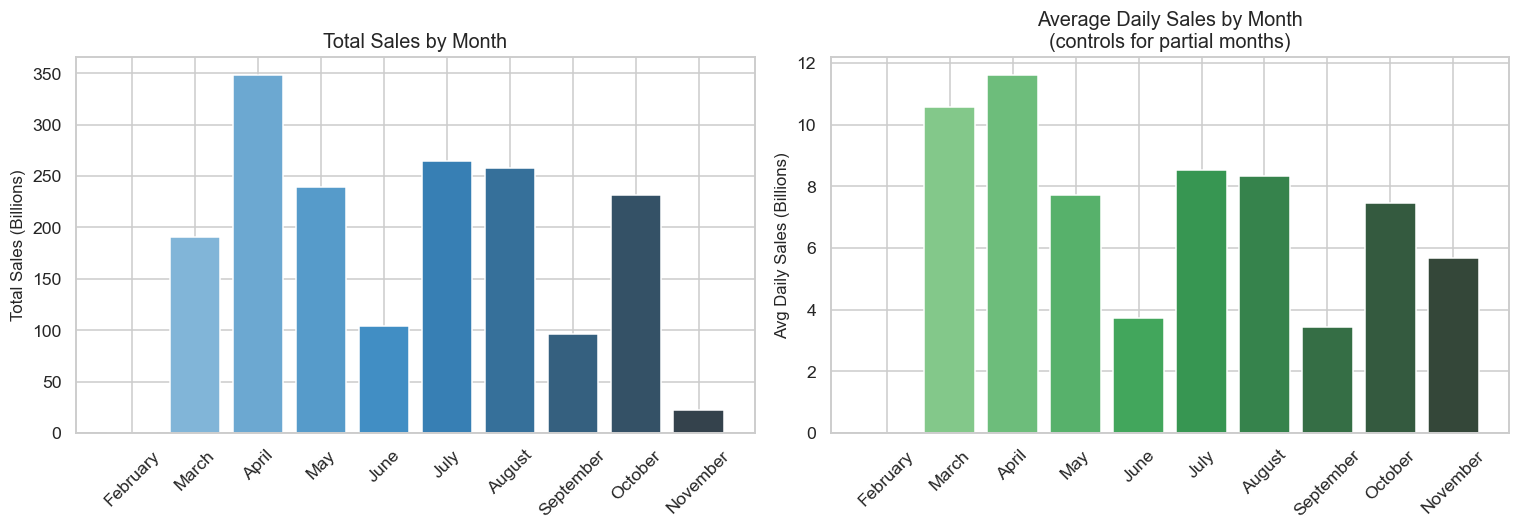


Monthly breakdown:
month_name  n_days  total_sales  avg_daily_sales  tickets_sold  avg_daily_tickets
  February       2     32210000     1.610500e+07           270         135.000000
     March      18 190503375738     1.058352e+10       1805330      100296.111111
     April      30 348614664007     1.162049e+10       4134613      137820.433333
       May      31 239595373317     7.728883e+09       3052733       98475.258065
      June      28 104001473893     3.714338e+09       1249595       44628.392857
      July      31 264855462688     8.543725e+09       2992026       96516.967742
    August      31 258296800764     8.332155e+09       2851380       91980.000000
 September      28  96569594964     3.448914e+09       1074979       38392.107143
   October      31 231675849820     7.473415e+09       2563955       82708.225806
  November       4  22708024998     5.677006e+09        220511       55127.750000


In [8]:
monthly = df.groupby("month").agg(
    total_sales=("total_sales", "sum"),
    tickets_sold=("tickets_sold", "sum"),
    n_days=("date", "nunique"),
).reset_index()
monthly["avg_daily_sales"] = monthly["total_sales"] / monthly["n_days"]
monthly["avg_daily_tickets"] = monthly["tickets_sold"] / monthly["n_days"]
monthly["month_name"] = pd.to_datetime(monthly["month"], format="%m").dt.strftime("%B")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

palette_blue = sns.color_palette("Blues_d", len(monthly))
palette_green = sns.color_palette("Greens_d", len(monthly))

axes[0].bar(monthly["month_name"], monthly["total_sales"] / 1e9,
            color=palette_blue, edgecolor="white")
axes[0].set_ylabel("Total Sales (Billions)")
axes[0].set_title("Total Sales by Month")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(monthly["month_name"], monthly["avg_daily_sales"] / 1e9,
            color=palette_green, edgecolor="white")
axes[1].set_ylabel("Avg Daily Sales (Billions)")
axes[1].set_title("Average Daily Sales by Month\n(controls for partial months)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
save_fig(fig, "monthly_sales.png")
plt.show()
plt.close("all")

print("\nMonthly breakdown:")
display_cols = ["month_name", "n_days", "total_sales", "avg_daily_sales",
                "tickets_sold", "avg_daily_tickets"]
print(monthly[display_cols].to_string(index=False))

## 7. Day-of-Week Patterns

Investigate the weekly demand cycle and quantify the weekend premium.

  Saved -> ..\reports\figures\day_of_week_patterns.png


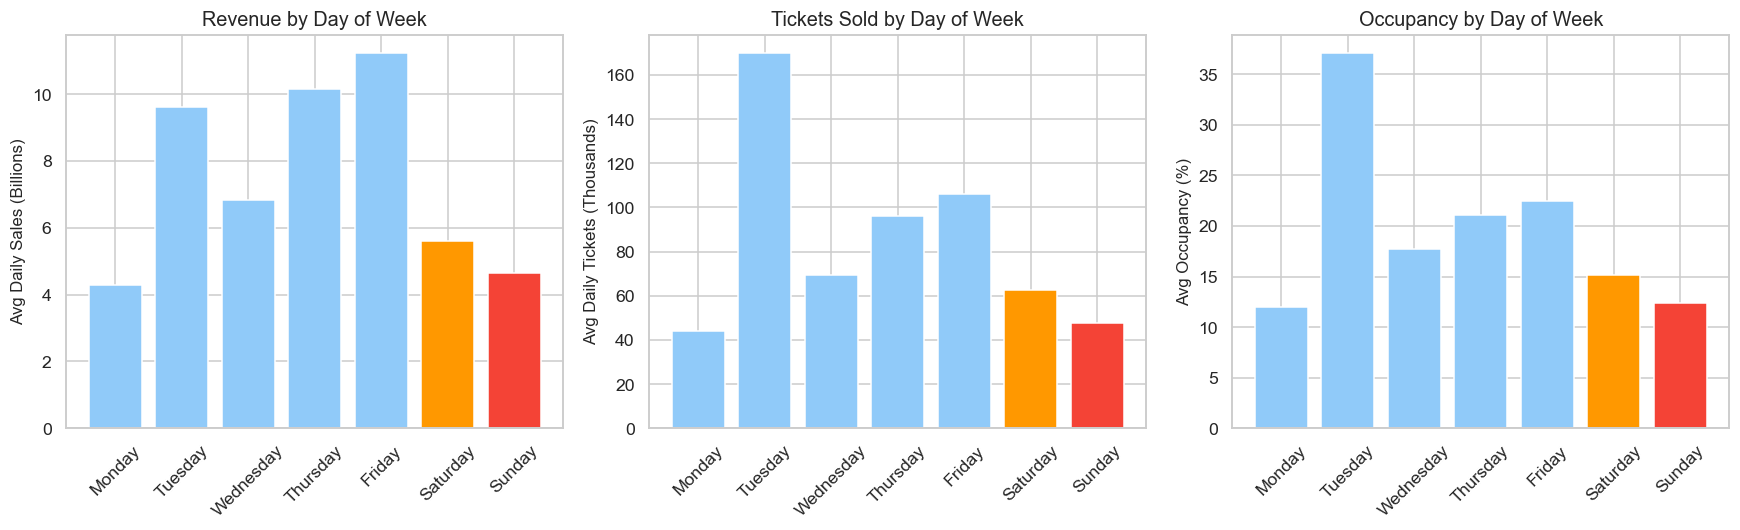


Day-of-week averages:
              avg_sales  avg_tickets  avg_occupancy  n_days
day_name                                                   
Monday     4.281360e+09     44038.75          12.00      32
Tuesday    9.612053e+09    169729.82          37.06      33
Wednesday  6.823317e+09     69458.03          17.70      33
Thursday   1.016486e+10     96103.97          21.05      33
Friday     1.122043e+10    105977.03          22.43      35
Saturday   5.621461e+09     62749.09          15.15      34
Sunday     4.652850e+09     47907.56          12.42      34


In [9]:
DOW_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

dow = daily.groupby("day_name").agg(
    avg_sales=("total_sales", "mean"),
    avg_tickets=("tickets_sold", "mean"),
    avg_occupancy=("occu_perc", "mean"),
    n_days=("date", "count"),
).reindex(DOW_ORDER)

# Highlight weekends
colors = ["#90CAF9"] * 5 + ["#FF9800", "#F44336"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(dow.index, dow["avg_sales"] / 1e9, color=colors, edgecolor="white")
axes[0].set_ylabel("Avg Daily Sales (Billions)")
axes[0].set_title("Revenue by Day of Week")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(dow.index, dow["avg_tickets"] / 1e3, color=colors, edgecolor="white")
axes[1].set_ylabel("Avg Daily Tickets (Thousands)")
axes[1].set_title("Tickets Sold by Day of Week")
axes[1].tick_params(axis="x", rotation=45)

axes[2].bar(dow.index, dow["avg_occupancy"], color=colors, edgecolor="white")
axes[2].set_ylabel("Avg Occupancy (%)")
axes[2].set_title("Occupancy by Day of Week")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
save_fig(fig, "day_of_week_patterns.png")
plt.show()
plt.close("all")

print("\nDay-of-week averages:")
print(dow.round(2).to_string())

=== Weekend vs Weekday (ISO Sat-Sun Definition) ===
Metric                        Mon-Fri        Sat-Sun      Ratio
--------------------------------------------------------------
Avg Daily Sales                 8.48B          5.14B      0.61x
Avg Daily Tickets              97.5K         55.3K      0.57x
Avg Occupancy                   22.1%          13.8%      0.62x

=== Regional Weekend (Thu-Fri) vs Workdays (Sat-Wed) ===
Thu-Fri Avg Daily Sales : 10.71B
Sat-Wed Avg Daily Sales : 6.20B
Thu-Fri Premium         : 1.73x


  Saved -> ..\reports\figures\weekend_vs_weekday.png


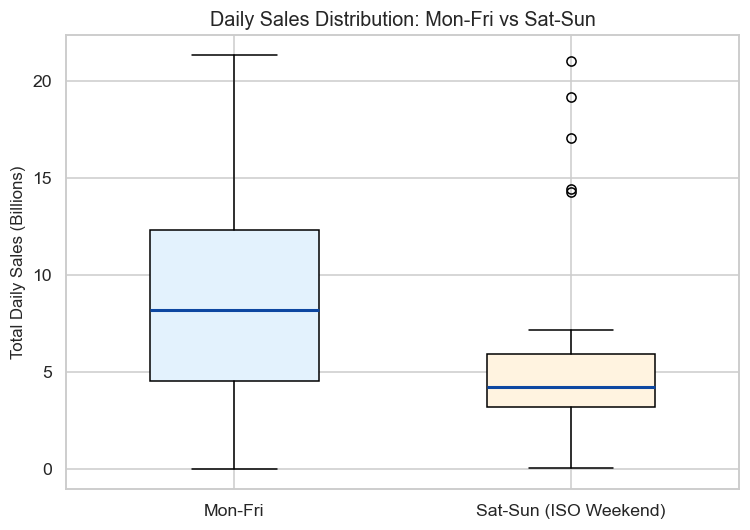

In [10]:
# Weekend vs Weekday comparison
weekend_daily = daily[daily["is_weekend"]]
weekday_daily = daily[~daily["is_weekend"]]

wd_sales = weekday_daily["total_sales"].mean()
we_sales = weekend_daily["total_sales"].mean()
wd_tickets = weekday_daily["tickets_sold"].mean()
we_tickets = weekend_daily["tickets_sold"].mean()
wd_occ = weekday_daily["occu_perc"].mean()
we_occ = weekend_daily["occu_perc"].mean()

print("=== Weekend vs Weekday (ISO Sat-Sun Definition) ===")
print(f"{'Metric':<22} {'Mon-Fri':>14} {'Sat-Sun':>14} {'Ratio':>10}")
print("-" * 62)
print(f"{'Avg Daily Sales':<22} {wd_sales/1e9:>13.2f}B {we_sales/1e9:>13.2f}B {we_sales/wd_sales:>9.2f}x")
print(f"{'Avg Daily Tickets':<22} {wd_tickets/1e3:>12.1f}K {we_tickets/1e3:>12.1f}K {we_tickets/wd_tickets:>9.2f}x")
print(f"{'Avg Occupancy':<22} {wd_occ:>13.1f}% {we_occ:>13.1f}% {we_occ/wd_occ:>9.2f}x")

# Regional weekend comparison (Thursday + Friday as weekend)
reg_weekend = daily[daily["day_name"].isin(["Thursday", "Friday"])]
reg_workday = daily[~daily["day_name"].isin(["Thursday", "Friday"])]
print("\n=== Regional Weekend (Thu-Fri) vs Workdays (Sat-Wed) ===")
print(f"Thu-Fri Avg Daily Sales : {reg_weekend['total_sales'].mean()/1e9:.2f}B")
print(f"Sat-Wed Avg Daily Sales : {reg_workday['total_sales'].mean()/1e9:.2f}B")
print(f"Thu-Fri Premium         : {reg_weekend['total_sales'].mean() / reg_workday['total_sales'].mean():.2f}x")

fig, ax = plt.subplots(figsize=(7, 5))
bplot = ax.boxplot(
    [weekday_daily["total_sales"] / 1e9, weekend_daily["total_sales"] / 1e9],
    labels=["Mon-Fri", "Sat-Sun (ISO Weekend)"], patch_artist=True, widths=0.5,
    medianprops=dict(color="#0D47A1", linewidth=2))
bplot["boxes"][0].set_facecolor("#E3F2FD")
bplot["boxes"][1].set_facecolor("#FFF3E0")
ax.set_ylabel("Total Daily Sales (Billions)")
ax.set_title("Daily Sales Distribution: Mon-Fri vs Sat-Sun")
plt.tight_layout()
save_fig(fig, "weekend_vs_weekday.png")
plt.show()
plt.close("all")

## 8. Sales by Film

Identify top-performing films and assess revenue concentration.
Only numeric `film_code` identifiers are available -- no film names or genres.

  Saved -> ..\reports\figures\top_10_films.png


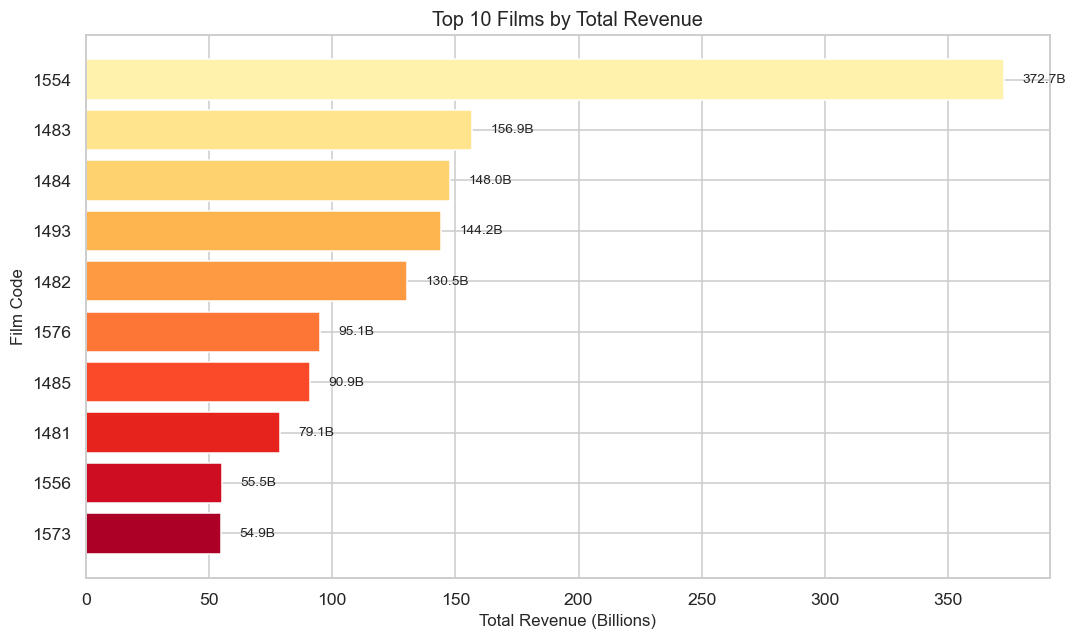


Revenue concentration:
  Top 5 films  (5/48 = 10%) -> 54.2% of total revenue
  Top 10 films (10/48 = 21%) -> 75.6% of total revenue

Top 10 detail:
 film_code  total_revenue  total_tickets  avg_occupancy  n_cinemas  n_dates
      1554   372740376637        4129543      25.345457        212      117
      1483   156913458770        1623569      26.206961        172      152
      1484   148011447334        1761782      28.015394        180      145
      1493   144169741258        1719867      19.414078        201      174
      1482   130526074406        1628821      28.347994        179      116
      1576    95057158934         968888      18.762609        144       39
      1485    90877218382         960897      27.392494        161      146
      1481    79051516436        1160989      24.203013        173      222
      1556    55480619968         635816      14.825815        197       86
      1573    54868553967         567610      19.642067        135       25


In [11]:
film_stats = df.groupby("film_code").agg(
    total_revenue=("total_sales", "sum"),
    total_tickets=("tickets_sold", "sum"),
    avg_occupancy=("occu_perc", "mean"),
    avg_price=("ticket_price", "mean"),
    n_cinemas=("cinema_code", "nunique"),
    n_dates=("date", "nunique"),
    n_records=("total_sales", "count"),
).sort_values("total_revenue", ascending=False).reset_index()

top10_films = film_stats.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
y_labels = top10_films["film_code"].astype(str).values[::-1]
values = top10_films["total_revenue"].values[::-1] / 1e9
bars = ax.barh(y_labels, values,
               color=sns.color_palette("YlOrRd_r", 10), edgecolor="white")
ax.set_xlabel("Total Revenue (Billions)")
ax.set_ylabel("Film Code")
ax.set_title("Top 10 Films by Total Revenue")
for bar, val in zip(bars, values):
    ax.text(val + max(values)*0.02, bar.get_y() + bar.get_height()/2,
            f"{val:.1f}B", va="center", fontsize=9)
plt.tight_layout()
save_fig(fig, "top_10_films.png")
plt.show()
plt.close("all")

# Revenue concentration
total_rev = film_stats["total_revenue"].sum()
film_stats["cum_pct"] = film_stats["total_revenue"].cumsum() / total_rev * 100
top5_pct = film_stats.head(5)["total_revenue"].sum() / total_rev * 100
top10_pct = film_stats.head(10)["total_revenue"].sum() / total_rev * 100

print(f"\nRevenue concentration:")
print(f"  Top 5 films  ({5}/48 = {5/48*100:.0f}%) -> {top5_pct:.1f}% of total revenue")
print(f"  Top 10 films (10/48 = {10/48*100:.0f}%) -> {top10_pct:.1f}% of total revenue")
print(f"\nTop 10 detail:")
print(top10_films[["film_code", "total_revenue", "total_tickets",
                    "avg_occupancy", "n_cinemas", "n_dates"]].to_string(index=False))

## 9. Sales by Cinema

Identify top-performing cinemas and the distribution of revenue across venues.

  Saved -> ..\reports\figures\top_10_cinemas.png


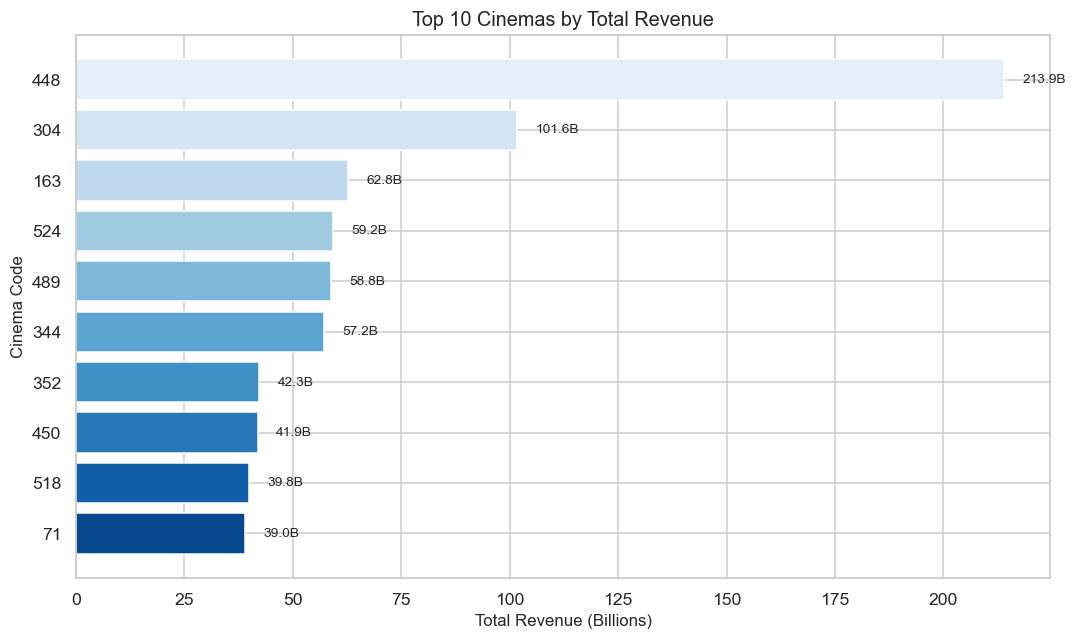


Cinema revenue concentration:
  Top  5 cinemas (5/246) -> 28.2% of revenue
  Top 20 cinemas (20/246) -> 57.2% of revenue

Top 10 detail:
 cinema_code  total_revenue  total_tickets  avg_occupancy  avg_capacity  n_films  n_dates
         448   213905979826        1683313      37.809855   1506.188339       47      225
         304   101602933000         786023      40.214557    913.440923       45      223
         163    62755809999         612029      34.266219    696.403186       48      225
         524    59235204992         493444      39.608629    587.274579       48      222
         489    58760547000         520199      32.401525    600.640504       48      223
         344    57186261000         449043      28.105755    821.792028       42      226
         352    42311035000         363423      22.764988    864.789810       39      223
         450    41880713998         333293      32.772219    659.103836       43      207
         518    39849453995         495912      26.7

In [12]:
cinema_stats = df.groupby("cinema_code").agg(
    total_revenue=("total_sales", "sum"),
    total_tickets=("tickets_sold", "sum"),
    avg_occupancy=("occu_perc", "mean"),
    avg_capacity=("capacity", "mean"),
    n_films=("film_code", "nunique"),
    n_dates=("date", "nunique"),
).sort_values("total_revenue", ascending=False).reset_index()

top10_cinemas = cinema_stats.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
y_labels = top10_cinemas["cinema_code"].astype(str).values[::-1]
values = top10_cinemas["total_revenue"].values[::-1] / 1e9
bars = ax.barh(y_labels, values,
               color=sns.color_palette("Blues_r", 10), edgecolor="white")
ax.set_xlabel("Total Revenue (Billions)")
ax.set_ylabel("Cinema Code")
ax.set_title("Top 10 Cinemas by Total Revenue")
for bar, val in zip(bars, values):
    ax.text(val + max(values)*0.02, bar.get_y() + bar.get_height()/2,
            f"{val:.1f}B", va="center", fontsize=9)
plt.tight_layout()
save_fig(fig, "top_10_cinemas.png")
plt.show()
plt.close("all")

cinema_total = cinema_stats["total_revenue"].sum()
c_top5  = cinema_stats.head(5)["total_revenue"].sum()  / cinema_total * 100
c_top20 = cinema_stats.head(20)["total_revenue"].sum() / cinema_total * 100
print(f"\nCinema revenue concentration:")
print(f"  Top  5 cinemas ({5}/{len(cinema_stats)}) -> {c_top5:.1f}% of revenue")
print(f"  Top 20 cinemas (20/{len(cinema_stats)}) -> {c_top20:.1f}% of revenue")
print(f"\nTop 10 detail:")
print(top10_cinemas[["cinema_code", "total_revenue", "total_tickets",
                      "avg_occupancy", "avg_capacity", "n_films",
                      "n_dates"]].to_string(index=False))

## 10. Occupancy Analysis

**Important methodological note:**
A simple average of `occu_perc` across records (unweighted) treats a 50-seat
show the same as a 2 000-seat show.  The **weighted** occupancy
(total tickets sold / total capacity) accounts for venue size and gives a more
accurate picture of overall seat utilisation.  Both are computed and compared below.

In [13]:
# Use only rows with valid capacity
valid = df[~df["capacity_invalid"]].copy()
print(f"Records with valid capacity: {len(valid):,} / {len(df):,}")

# Unweighted vs weighted
unweighted_occ = valid["occu_perc"].mean()
weighted_occ   = valid["tickets_sold"].sum() / valid["capacity"].sum() * 100

print(f"\n=== Occupancy Comparison ===")
print(f"  Unweighted mean (simple avg of occu_perc) : {unweighted_occ:.2f}%")
print(f"  Weighted   (total tickets / total capacity): {weighted_occ:.2f}%")
diff = weighted_occ - unweighted_occ
direction = "higher" if diff > 0 else "lower"
print(f"  Difference: {abs(diff):.2f} pp -- weighted is {direction}")
if direction == "higher":
    print("  Interpretation: larger-capacity venues tend to fill a greater")
    print("  share of seats, pulling the weighted average up.")
else:
    print("  Interpretation: larger-capacity venues tend to have lower fill")
    print("  rates, pulling the weighted average down.")

Records with valid capacity: 142,363 / 142,418

=== Occupancy Comparison ===
  Unweighted mean (simple avg of occu_perc) : 19.95%
  Weighted   (total tickets / total capacity): 16.39%
  Difference: 3.56 pp -- weighted is lower
  Interpretation: larger-capacity venues tend to have lower fill
  rates, pulling the weighted average down.


  Saved -> ..\reports\figures\occupancy_analysis.png


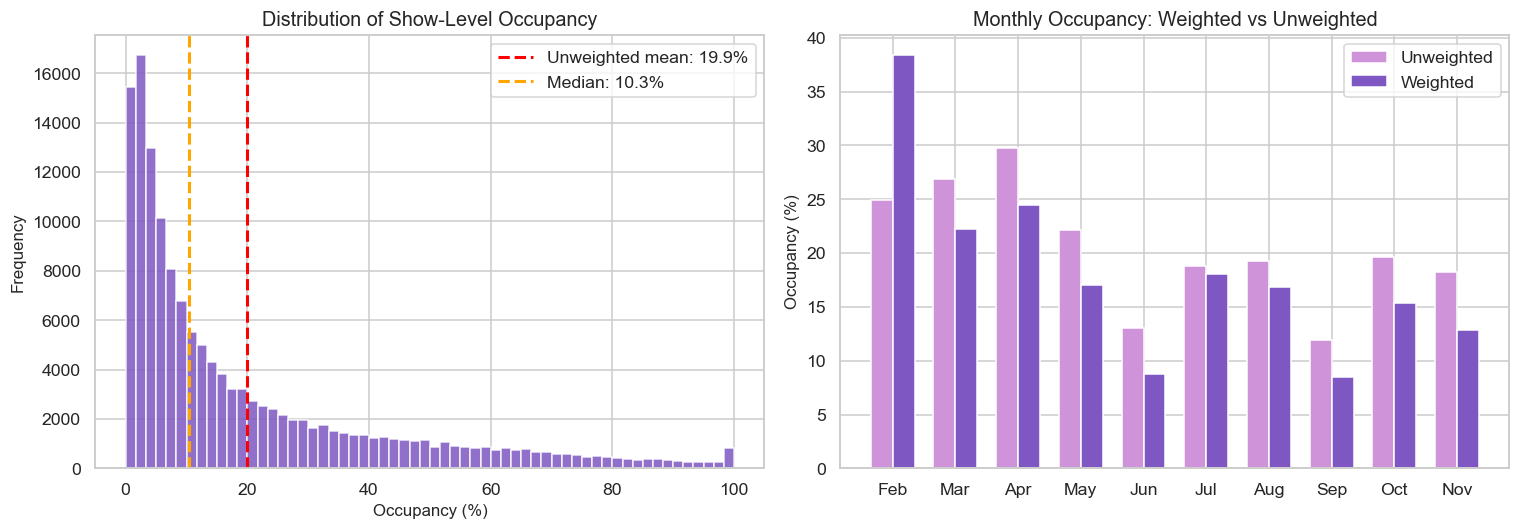

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution
axes[0].hist(valid["occu_perc"], bins=60, edgecolor="white", alpha=0.85,
             color="#7E57C2")
axes[0].axvline(unweighted_occ, color="red", ls="--", lw=2,
                label=f"Unweighted mean: {unweighted_occ:.1f}%")
axes[0].axvline(valid["occu_perc"].median(), color="orange", ls="--", lw=2,
                label=f"Median: {valid['occu_perc'].median():.1f}%")
axes[0].set_xlabel("Occupancy (%)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Show-Level Occupancy")
axes[0].legend()

# Monthly weighted vs unweighted
mo = valid.groupby("month").agg(
    tix_sum=("tickets_sold", "sum"),
    cap_sum=("capacity", "sum"),
    unwt=("occu_perc", "mean"),
).reset_index()
mo["wt"] = mo["tix_sum"] / mo["cap_sum"] * 100
month_labels = pd.to_datetime(mo["month"], format="%m").dt.strftime("%b")

x = np.arange(len(mo))
w = 0.35
axes[1].bar(x - w/2, mo["unwt"], w, label="Unweighted", color="#CE93D8", edgecolor="white")
axes[1].bar(x + w/2, mo["wt"],   w, label="Weighted",   color="#7E57C2", edgecolor="white")
axes[1].set_xticks(x)
axes[1].set_xticklabels(month_labels)
axes[1].set_ylabel("Occupancy (%)")
axes[1].set_title("Monthly Occupancy: Weighted vs Unweighted")
axes[1].legend()

plt.tight_layout()
save_fig(fig, "occupancy_analysis.png")
plt.show()
plt.close("all")

In [15]:
# Occupancy buckets
buckets = [
    ("<5%", (valid["occu_perc"] < 5).sum()),
    ("5-10%", ((valid["occu_perc"] >= 5) & (valid["occu_perc"] < 10)).sum()),
    ("10-25%", ((valid["occu_perc"] >= 10) & (valid["occu_perc"] < 25)).sum()),
    ("25-50%", ((valid["occu_perc"] >= 25) & (valid["occu_perc"] < 50)).sum()),
    ("50-75%", ((valid["occu_perc"] >= 50) & (valid["occu_perc"] < 75)).sum()),
    ("75-100%", (valid["occu_perc"] >= 75).sum()),
]
print("=== Occupancy Distribution Buckets ===")
print(f"{'Bucket':<12} {'Count':>10} {'Share':>8}")
print("-" * 32)
for label, cnt in buckets:
    print(f"{label:<12} {cnt:>10,} {cnt/len(valid)*100:>7.1f}%")

low_occ_pct = (valid["occu_perc"] < 10).sum() / len(valid) * 100
print(f"\nKey stat: {low_occ_pct:.1f}% of shows run below 10% occupancy.")

=== Occupancy Distribution Buckets ===
Bucket            Count    Share
--------------------------------
<5%              44,679    31.4%
5-10%            25,056    17.6%
10-25%           32,917    23.1%
25-50%           22,198    15.6%
50-75%           11,667     8.2%
75-100%           5,846     4.1%

Key stat: 49.0% of shows run below 10% occupancy.


## 11. Ticket Price Analysis

Examine the price distribution and the price-demand relationship.
Prices appear to be in **Iranian Rial** based on their magnitude (50K - 200K per ticket).

  Saved -> ..\reports\figures\ticket_price_analysis.png


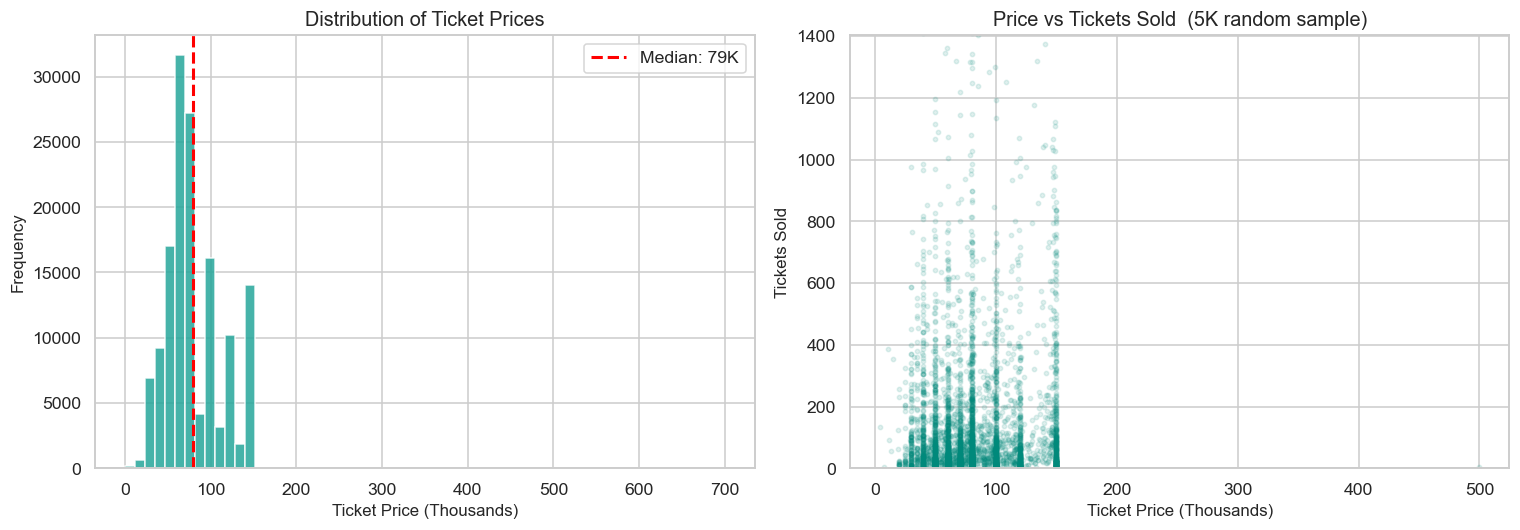


Price stats:
  P10: 40.0K
  P25: 60.0K
  Median: 79.4K
  P75: 100.0K
  P90: 139.7K
  Min: 0.5K
  Max: 700.0K


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution
axes[0].hist(df["ticket_price"] / 1e3, bins=60, edgecolor="white",
             alpha=0.85, color="#26A69A")
axes[0].axvline(df["ticket_price"].median() / 1e3, color="red", ls="--", lw=2,
                label=f"Median: {df['ticket_price'].median()/1e3:.0f}K")
axes[0].set_xlabel("Ticket Price (Thousands)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Ticket Prices")
axes[0].legend()

# Price vs demand (sampled scatter)
rng = np.random.default_rng(42)
idx = rng.choice(len(df), size=min(5000, len(df)), replace=False)
sample = df.iloc[idx]
axes[1].scatter(sample["ticket_price"] / 1e3, sample["tickets_sold"],
                alpha=0.12, s=8, color="#00897B")
axes[1].set_xlabel("Ticket Price (Thousands)")
axes[1].set_ylabel("Tickets Sold")
axes[1].set_title("Price vs Tickets Sold  (5K random sample)")
axes[1].set_ylim(0, sample["tickets_sold"].quantile(0.99))

plt.tight_layout()
save_fig(fig, "ticket_price_analysis.png")
plt.show()
plt.close("all")

print(f"\nPrice stats:")
for pct, label in [(10, "P10"), (25, "P25"), (50, "Median"),
                    (75, "P75"), (90, "P90")]:
    print(f"  {label}: {df['ticket_price'].quantile(pct/100)/1e3:.1f}K")
print(f"  Min: {df['ticket_price'].min()/1e3:.1f}K")
print(f"  Max: {df['ticket_price'].max()/1e3:.1f}K")

## 12. Outlier & Anomaly Detection

Box plots for key metrics and identification of unusual days.

  Saved -> ..\reports\figures\outlier_boxplots.png


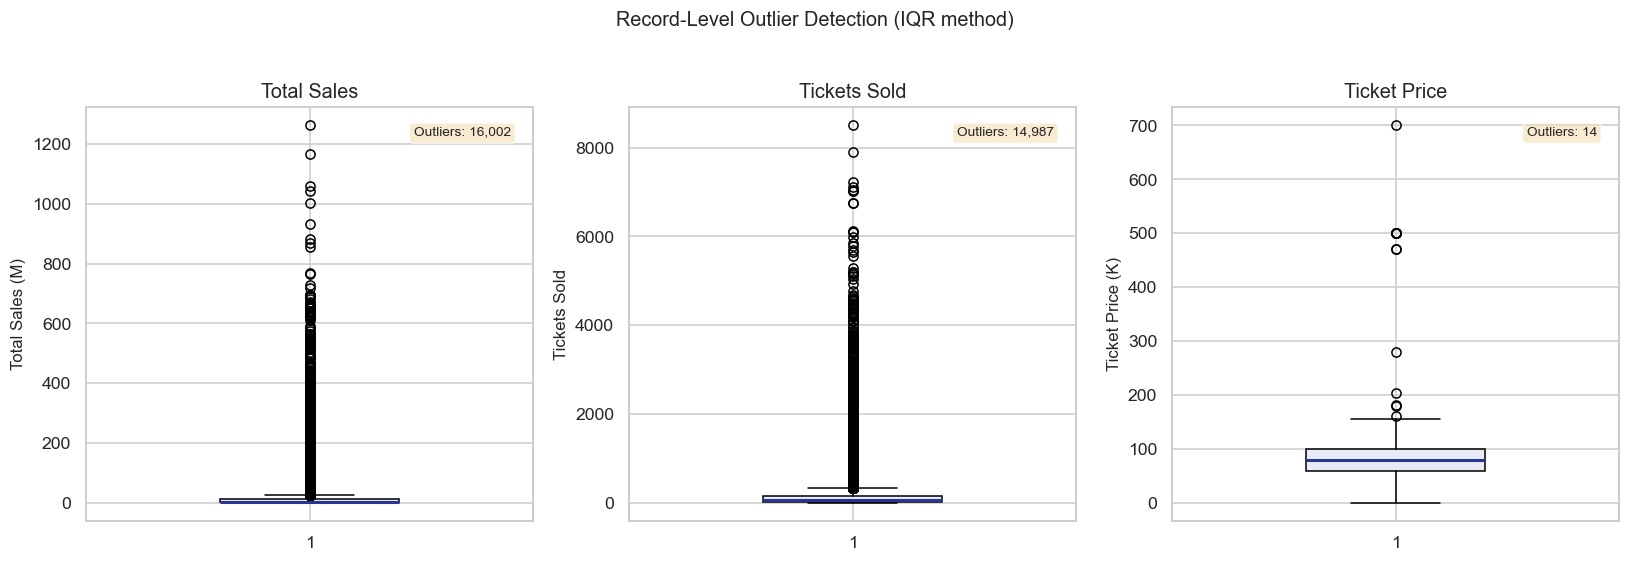

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col, label, div, unit in zip(
    axes,
    ["total_sales", "tickets_sold", "ticket_price"],
    ["Total Sales", "Tickets Sold", "Ticket Price"],
    [1e6, 1, 1e3],
    ["M", "", "K"],
):
    data = df[col] / div
    bp = ax.boxplot(data, patch_artist=True, widths=0.4,
                    boxprops=dict(facecolor="#E8EAF6"),
                    medianprops=dict(color="#283593", linewidth=2))
    ax.set_ylabel(f"{label} ({unit})" if unit else label)
    ax.set_title(f"{label}")
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1
    n_out = ((data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)).sum()
    ax.text(0.95, 0.95, f"Outliers: {n_out:,}", transform=ax.transAxes,
            ha="right", va="top", fontsize=9,
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.6))

plt.suptitle("Record-Level Outlier Detection (IQR method)", y=1.02, fontsize=13)
plt.tight_layout()
save_fig(fig, "outlier_boxplots.png")
plt.show()
plt.close("all")

In [18]:
# Top and bottom revenue days (excluding sparse ramp-up)
main_daily = daily[daily["n_records"] >= 50]

top5_days = main_daily.nlargest(5, "total_sales")
bot5_days = main_daily.nsmallest(5, "total_sales")

print("=== Top 5 Highest-Revenue Days ===")
for _, r in top5_days.iterrows():
    print(f"  {r['date'].date()} ({r['day_name']:<9s})  "
          f"Sales: {r['total_sales']/1e9:.2f}B  "
          f"Tickets: {r['tickets_sold']:,.0f}  "
          f"Films: {r['n_films']}")

print("\n=== Bottom 5 Revenue Days (main period) ===")
for _, r in bot5_days.iterrows():
    print(f"  {r['date'].date()} ({r['day_name']:<9s})  "
          f"Sales: {r['total_sales']/1e9:.2f}B  "
          f"Tickets: {r['tickets_sold']:,.0f}  "
          f"Films: {r['n_films']}")

=== Top 5 Highest-Revenue Days ===
  2018-03-27 (Tuesday  )  Sales: 21.32B  Tickets: 218,718  Films: 7
  2018-04-01 (Sunday   )  Sales: 21.05B  Tickets: 197,341  Films: 7
  2018-04-13 (Friday   )  Sales: 19.76B  Tickets: 198,227  Films: 7
  2018-03-30 (Friday   )  Sales: 19.26B  Tickets: 182,806  Films: 7
  2018-03-31 (Saturday )  Sales: 19.18B  Tickets: 182,239  Films: 7

=== Bottom 5 Revenue Days (main period) ===
  2018-03-20 (Tuesday  )  Sales: 0.26B  Tickets: 4,028  Films: 7
  2018-09-18 (Tuesday  )  Sales: 0.54B  Tickets: 9,388  Films: 18
  2018-11-04 (Sunday   )  Sales: 0.68B  Tickets: 7,584  Films: 15
  2018-10-29 (Monday   )  Sales: 0.86B  Tickets: 9,738  Films: 17
  2018-09-17 (Monday   )  Sales: 0.88B  Tickets: 8,820  Films: 19


## 13. Correlation Analysis

Linear relationships between key numeric variables.

**Caveat:** Correlation does not imply causation.
`total_sales = tickets_sold x ticket_price` by definition, so their
correlation is mechanical, not a finding.

  Saved -> ..\reports\figures\correlation_heatmap.png


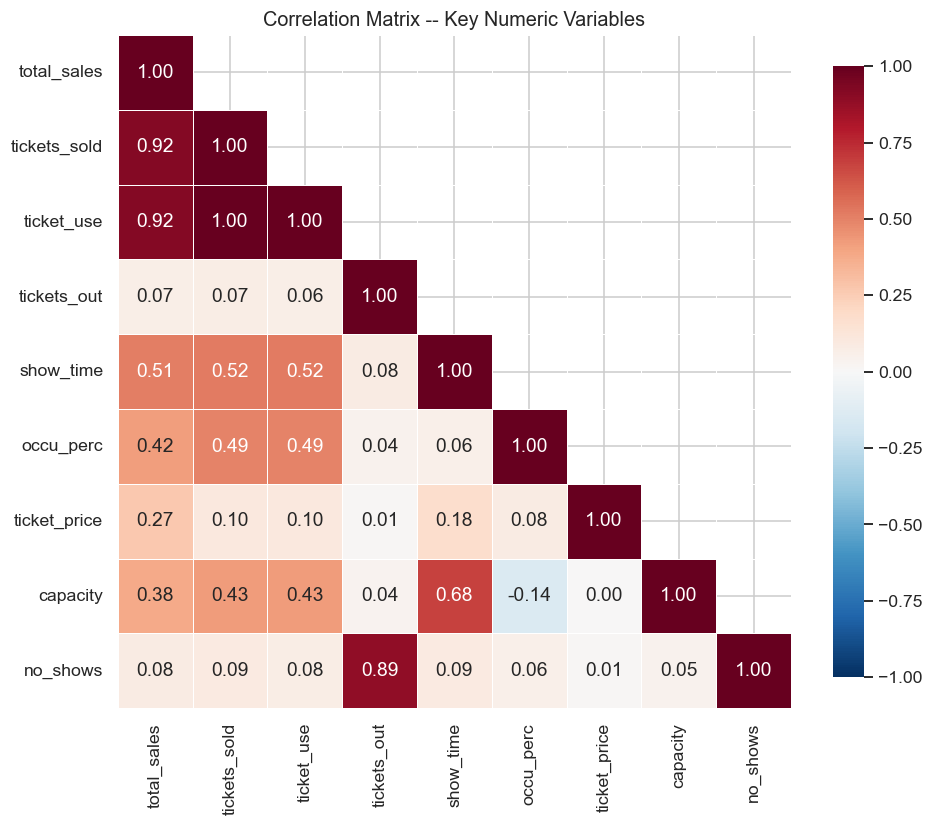


=== Notable Correlations (|r| > 0.5, excluding definitional) ===
  total_sales     <-> ticket_use       r = +0.915
  total_sales     <-> show_time        r = +0.510
  tickets_sold    <-> show_time        r = +0.522
  ticket_use      <-> show_time        r = +0.522
  tickets_out     <-> no_shows         r = +0.887
  show_time       <-> capacity         r = +0.682


In [19]:
corr_cols = ["total_sales", "tickets_sold", "ticket_use", "tickets_out",
             "show_time", "occu_perc", "ticket_price", "capacity", "no_shows"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Correlation Matrix -- Key Numeric Variables")
plt.tight_layout()
save_fig(fig, "correlation_heatmap.png")
plt.show()
plt.close("all")

print("\n=== Notable Correlations (|r| > 0.5, excluding definitional) ===")
definitional = {("total_sales", "tickets_sold"), ("tickets_sold", "total_sales"),
                ("tickets_sold", "ticket_use"), ("ticket_use", "tickets_sold")}
for i in range(len(corr_cols)):
    for j in range(i+1, len(corr_cols)):
        r = corr.iloc[i, j]
        pair = (corr_cols[i], corr_cols[j])
        if abs(r) > 0.5 and pair not in definitional:
            print(f"  {corr_cols[i]:15s} <-> {corr_cols[j]:15s}  r = {r:+.3f}")

## 14. No-Show Analysis

The gap between `tickets_sold` and `ticket_use` indicates tickets purchased but
not scanned at the gate (no-shows, cancellations, or data adjustments).

Records with no-shows: 6,121 (4.3%)
Total no-show tickets: 31,523
Overall no-show rate : 0.16% of tickets sold


  Saved -> ..\reports\figures\noshow_by_day.png


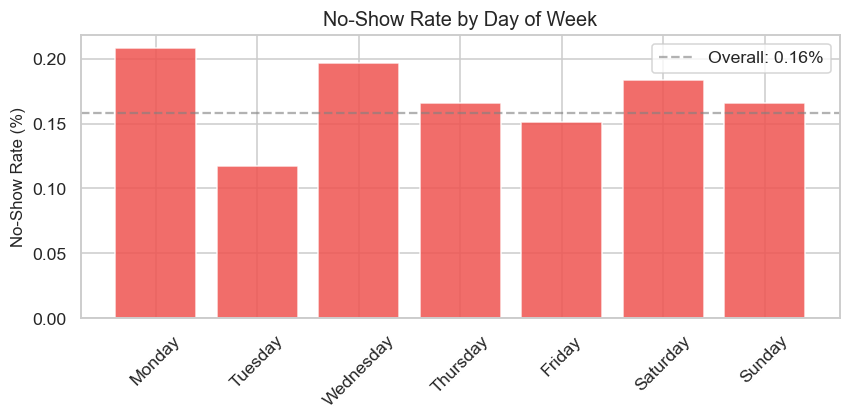

In [20]:
has_ns = df[df["no_shows"] > 0]
overall_ns_rate = df["no_shows"].sum() / df["tickets_sold"].sum() * 100

print(f"Records with no-shows: {len(has_ns):,} ({len(has_ns)/len(df)*100:.1f}%)")
print(f"Total no-show tickets: {df['no_shows'].sum():,}")
print(f"Overall no-show rate : {overall_ns_rate:.2f}% of tickets sold")

# By day of week
dow_ns = df.groupby("day_name").agg(
    ns=("no_shows", "sum"), ts=("tickets_sold", "sum")
).reindex(DOW_ORDER)
dow_ns["rate"] = dow_ns["ns"] / dow_ns["ts"] * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(dow_ns.index, dow_ns["rate"], color="#EF5350", edgecolor="white", alpha=0.85)
ax.set_ylabel("No-Show Rate (%)")
ax.set_title("No-Show Rate by Day of Week")
ax.tick_params(axis="x", rotation=45)
ax.axhline(overall_ns_rate, color="gray", ls="--", alpha=0.6,
           label=f"Overall: {overall_ns_rate:.2f}%")
ax.legend()
plt.tight_layout()
save_fig(fig, "noshow_by_day.png")
plt.show()
plt.close("all")

---

## 15. Key Findings

Each finding below is supported by a calculated metric or chart produced above.
Findings state **observations**; possible explanations are noted separately.

In [21]:
# Pre-compute all finding metrics
total_revenue = df["total_sales"].sum()

# F1 - concentration
f1_pct = film_stats.head(5)["total_revenue"].sum() / total_revenue * 100

# F2 - weekend
weekend_ratio = we_sales / wd_sales

# F3 - occupancy
f3_low = (valid["occu_perc"] < 10).sum() / len(valid) * 100

# F4 - monthly peak/trough
peak_mo = monthly.loc[monthly["avg_daily_sales"].idxmax()]
trough_mo = monthly.loc[monthly["avg_daily_sales"].idxmin()]

# F5 - no-show
f5_rate = overall_ns_rate

print("=" * 70)
print("  VERIFIED KEY FINDINGS")
print("=" * 70)
print()
print(f"1. REVENUE IS CONCENTRATED IN A FEW FILMS")
print(f"   Top 5 films (of 48) generate {f1_pct:.1f}% of total revenue.")
print(f"   Evidence: top_10_films.png")
print()
print(f"2. PEAK DEMAND CONCENTRATED ON THURSDAY, FRIDAY, AND TUESDAY")
print(f"   Friday (11.22B) and Thursday (10.16B) lead daily revenue, with Tuesday")
print(f"   driving massive ticket volume (169.7K tickets, 37.1% occupancy).")
print(f"   Note: Standard Western Sat-Sun definition yields 5.14B/day vs Mon-Fri 8.48B/day,")
print(f"   reflecting Middle Eastern workweek patterns where Thu-Fri is the weekend (10.69B/day).")
print(f"   Evidence: day_of_week_patterns.png, weekend_vs_weekday.png")
print()
print(f"3. MOST SHOWS ARE POORLY ATTENDED")
print(f"   {f3_low:.1f}% of shows run below 10% occupancy.")
print(f"   Weighted overall occupancy: {weighted_occ:.1f}%")
print(f"   (vs unweighted mean: {unweighted_occ:.1f}%)")
print(f"   Evidence: occupancy_analysis.png")
print()
print(f"4. CLEAR MONTHLY DEMAND VARIATION")
print(f"   Peak avg daily sales  : {peak_mo['month_name']} ({peak_mo['avg_daily_sales']/1e9:.2f}B/day)")
print(f"   Trough avg daily sales: {trough_mo['month_name']} ({trough_mo['avg_daily_sales']/1e9:.2f}B/day)")
print(f"   Evidence: monthly_sales.png")
print()
print(f"5. NO-SHOW RATE IS LOW BUT MEASURABLE")
print(f"   Overall rate: {f5_rate:.2f}% of tickets sold.")
print(f"   {len(has_ns):,} records have at least one no-show.")
print(f"   Evidence: noshow_by_day.png")
print()
print("=" * 70)

  VERIFIED KEY FINDINGS

1. REVENUE IS CONCENTRATED IN A FEW FILMS
   Top 5 films (of 48) generate 54.2% of total revenue.
   Evidence: top_10_films.png

2. PEAK DEMAND CONCENTRATED ON THURSDAY, FRIDAY, AND TUESDAY
   Friday (11.22B) and Thursday (10.16B) lead daily revenue, with Tuesday
   driving massive ticket volume (169.7K tickets, 37.1% occupancy).
   Note: Standard Western Sat-Sun definition yields 5.14B/day vs Mon-Fri 8.48B/day,
   reflecting Middle Eastern workweek patterns where Thu-Fri is the weekend (10.69B/day).
   Evidence: day_of_week_patterns.png, weekend_vs_weekday.png

3. MOST SHOWS ARE POORLY ATTENDED
   49.0% of shows run below 10% occupancy.
   Weighted overall occupancy: 16.4%
   (vs unweighted mean: 19.9%)
   Evidence: occupancy_analysis.png

4. CLEAR MONTHLY DEMAND VARIATION
   Peak avg daily sales  : April (11.62B/day)
   Trough avg daily sales: February (0.02B/day)
   Evidence: monthly_sales.png

5. NO-SHOW RATE IS LOW BUT MEASURABLE
   Overall rate: 0.16% of 

## 16. Risks & Opportunities

Derived from the analysis above -- not from external assumptions.

In [22]:
print("=== RISKS ===")
print()
print("1. LOW OCCUPANCY")
print("   Observation: 49% of shows run below 10% occupancy.")
print("   Risk: These low-fill screenings fail to cover theater overhead/operating costs.")
print("   Possible explanation: Unpopular time slots, long film runs past peak popularity,")
print("   or oversized screening halls for niche films.")
print()
print("2. REVENUE CONCENTRATION")
print("   Observation: Top 5 films generate 54.2% of total revenue.")
print("   Risk: Revenue is vulnerable to release-schedule volatility outside operator control.")
print()
print("3. EARLY-WEEK DEMAND LULL")
print("   Observation: Monday (4.28B), Sunday (4.65B), and Saturday (5.62B) generate")
print("   less than half the revenue of peak days (Thursday/Friday >10B).")
print("   Risk: Theater capacity is significantly underutilized during early workweek days.")
print()
print("4. DATA QUALITY GAPS")
print("   Observation: 55 records have invalid capacity; 61 had negative ticket_use.")
print("   Risk: Small but could bias occupancy/no-show analysis if not filtered.")
print()
print()
print("=== OPPORTUNITIES ===")
print()
print("1. OFF-PEAK PROMOTIONS & TUESDAY MODEL REPLICATION")
print("   Tuesday demonstrates that volume incentives work (169.7K tickets, 37.1% occupancy).")
print("   Cinemas could introduce targeted promotions or matinee discounts on Monday/Sunday.")
print()
print("2. SCHEDULE OPTIMISATION")
print("   Shows with persistently <5% occupancy could be shifted to smaller auditoriums,")
print("   consolidated into fewer showtimes, or replaced with higher-demand titles.")
print()
print("3. DYNAMIC / OCCUPANCY-BASED PRICING")
print("   High-demand films and peak Thursday/Friday evening slots (>50% occupancy)")
print("   support premium pricing tiers to maximize yield.")
print()
print("4. NO-SHOW RECOVERY")
print("   Targeted digital reminders and re-release of unclaimed seats")
print("   could recover seats without hurting attendee experience.")

=== RISKS ===

1. LOW OCCUPANCY
   Observation: 49% of shows run below 10% occupancy.
   Risk: These low-fill screenings fail to cover theater overhead/operating costs.
   Possible explanation: Unpopular time slots, long film runs past peak popularity,
   or oversized screening halls for niche films.

2. REVENUE CONCENTRATION
   Observation: Top 5 films generate 54.2% of total revenue.
   Risk: Revenue is vulnerable to release-schedule volatility outside operator control.

3. EARLY-WEEK DEMAND LULL
   Observation: Monday (4.28B), Sunday (4.65B), and Saturday (5.62B) generate
   less than half the revenue of peak days (Thursday/Friday >10B).
   Risk: Theater capacity is significantly underutilized during early workweek days.

4. DATA QUALITY GAPS
   Observation: 55 records have invalid capacity; 61 had negative ticket_use.
   Risk: Small but could bias occupancy/no-show analysis if not filtered.


=== OPPORTUNITIES ===

1. OFF-PEAK PROMOTIONS & TUESDAY MODEL REPLICATION
   Tuesday demon

## 17. Data Limitations

These limitations constrain the strength of conclusions and the scope of forecasting.

In [23]:
print("=== DATA LIMITATIONS ===")
print()
print("1. SINGLE YEAR, PARTIAL COVERAGE")
print("   Only Feb-Nov 2018 (~8.5 months). No year-over-year comparison.")
print("   Dec and Jan are missing entirely.")
print()
print("2. NO FILM METADATA")
print("   Only numeric film_code. Genre, cast, marketing budget unknown.")
print("   Cannot attribute drivers to film characteristics.")
print()
print("3. NO CINEMA METADATA")
print("   No names, locations, or chain info. Geographic analysis impossible.")
print()
print("4. CURRENCY UNSPECIFIED")
print("   Likely Iranian Rial based on magnitudes, but unconfirmed.")
print()
print("5. CAPACITY IS DERIVED")
print("   Fractional values suggest back-calculation, not raw seat counts.")
print()
print("6. NO EXTERNAL FACTORS")
print("   Holidays, weather, competing entertainment -- not captured.")
print("   Limits causal interpretation of demand patterns.")
print()
print("7. SPARSE EARLY PERIOD")
print("   Feb 21 - Mar 13 has very few records per day.")
print("   May reflect data-collection ramp-up, not actual low activity.")

=== DATA LIMITATIONS ===

1. SINGLE YEAR, PARTIAL COVERAGE
   Only Feb-Nov 2018 (~8.5 months). No year-over-year comparison.
   Dec and Jan are missing entirely.

2. NO FILM METADATA
   Only numeric film_code. Genre, cast, marketing budget unknown.
   Cannot attribute drivers to film characteristics.

3. NO CINEMA METADATA
   No names, locations, or chain info. Geographic analysis impossible.

4. CURRENCY UNSPECIFIED
   Likely Iranian Rial based on magnitudes, but unconfirmed.

5. CAPACITY IS DERIVED
   Fractional values suggest back-calculation, not raw seat counts.

6. NO EXTERNAL FACTORS
   Holidays, weather, competing entertainment -- not captured.
   Limits causal interpretation of demand patterns.

7. SPARSE EARLY PERIOD
   Feb 21 - Mar 13 has very few records per day.
   May reflect data-collection ramp-up, not actual low activity.


## 18. Dashboard Page Recommendations

Based on EDA findings, the following metrics and charts belong on each planned page.

In [24]:
print("=== PAGE 1: EXECUTIVE OVERVIEW ===")
print()
print("KPI Cards:")
print("  - Total revenue (all time)")
print("  - Total tickets sold")
print("  - Average daily revenue")
print("  - Overall weighted occupancy %")
print("  - Active films / cinemas count")
print()
print("Charts:")
print("  - Daily sales trend with rolling average  (daily_sales_trends.png)")
print("  - Monthly sales bars                      (monthly_sales.png)")
print("  - Weekend vs Weekday box plot             (weekend_vs_weekday.png)")
print()
print("Filters: Date range selector")
print()
print()
print("=== PAGE 2: SALES PERFORMANCE ===")
print()
print("Charts:")
print("  - Top 10 films by revenue                (top_10_films.png)")
print("  - Top 10 cinemas by revenue              (top_10_cinemas.png)")
print("  - Day-of-week patterns                   (day_of_week_patterns.png)")
print("  - Occupancy distribution + weighted/unwt  (occupancy_analysis.png)")
print()
print("Tables:")
print("  - Film performance table (sortable)")
print("  - Cinema performance table (sortable)")
print()
print("Filters: Film code, Cinema code, Date range")
print()
print()
print("=== PAGE 3: FORECAST, RISK & DECISIONS ===")
print()
print("Charts:")
print("  - Sales forecast with confidence bands")
print("  - No-show rate trends                    (noshow_by_day.png)")
print("  - Outlier/anomaly timeline               (outlier_boxplots.png)")
print()
print("Risk flags:")
print("  - Low occupancy alerts (< 10%)")
print("  - Revenue concentration warning")
print("  - Weekday underperformance indicator")
print()
print("Recommendations panel:")
print("  - Weekday promotion opportunity")
print("  - Schedule optimisation candidates")
print("  - Pricing suggestions")

=== PAGE 1: EXECUTIVE OVERVIEW ===

KPI Cards:
  - Total revenue (all time)
  - Total tickets sold
  - Average daily revenue
  - Overall weighted occupancy %
  - Active films / cinemas count

Charts:
  - Daily sales trend with rolling average  (daily_sales_trends.png)
  - Monthly sales bars                      (monthly_sales.png)
  - Weekend vs Weekday box plot             (weekend_vs_weekday.png)

Filters: Date range selector


=== PAGE 2: SALES PERFORMANCE ===

Charts:
  - Top 10 films by revenue                (top_10_films.png)
  - Top 10 cinemas by revenue              (top_10_cinemas.png)
  - Day-of-week patterns                   (day_of_week_patterns.png)
  - Occupancy distribution + weighted/unwt  (occupancy_analysis.png)

Tables:
  - Film performance table (sortable)
  - Cinema performance table (sortable)

Filters: Film code, Cinema code, Date range


=== PAGE 3: FORECAST, RISK & DECISIONS ===

Charts:
  - Sales forecast with confidence bands
  - No-show rate trends        

---

**End of Exploratory Data Analysis -- Phase 3**

All findings are derived from the actual cleaned Cinema Ticket dataset.
Figures have been saved to `reports/figures/` for reuse in the dashboard.